In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def odeEuler(f,t,y0):
    """Método de Euler para y' = f(t,y), y(t[0]) = y0.
    Funciona para equações escalares (y0 número) e para sistemas (y0 lista/array)."""
    y0 = np.asarray(y0, dtype=float)
    y = np.zeros((len(t),) + y0.shape)
    y[0] = y0
    for n in range(0,len(t)-1):
        h = t[n+1] - t[n]
        k1 = np.asarray(f(t[n],y[n]))
        y[n+1] = y[n] + k1*h
    return y

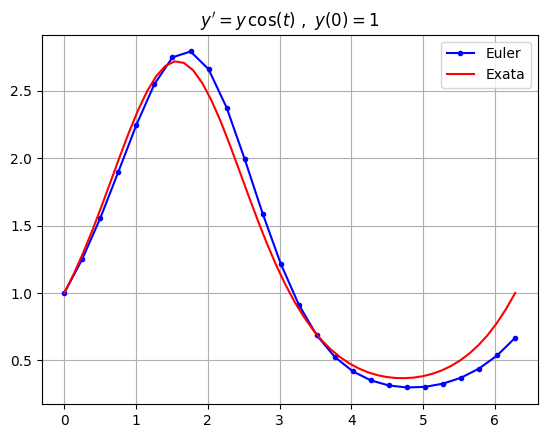

In [3]:
f = lambda t,y: y*np.cos(t)
y0 = 1; t0 = 0; tf = 2*np.pi;
N = 25; t = np.linspace(t0,tf,N+1)   # N passos: h = 2*pi/25 = 0.251...
y = odeEuler(f,t,y0)
plt.plot(t,y,'b.-')
t_exact = np.linspace(t0,tf,50)
y_exact = np.exp(np.sin(t_exact))
plt.plot(t_exact,y_exact,'r')
plt.grid(True), plt.title(r"$y' = y \, \cos(t) \ , \ y(0)=1$")
plt.legend(["Euler","Exata"])
plt.show()

In [4]:
def odeHeun(f,t,y0):
    """Método de Heun para y' = f(t,y), y(t[0]) = y0 (escalar ou sistema)."""
    y0 = np.asarray(y0, dtype=float)
    y = np.zeros((len(t),) + y0.shape)
    y[0] = y0
    for n in range(0,len(t)-1):
        h = t[n+1] - t[n]
        k1 = np.asarray(f(t[n],y[n]))
        k2 = np.asarray(f(t[n+1],y[n] + k1*h))
        y[n+1] = y[n] + (k1 + k2)/2*h
    return y

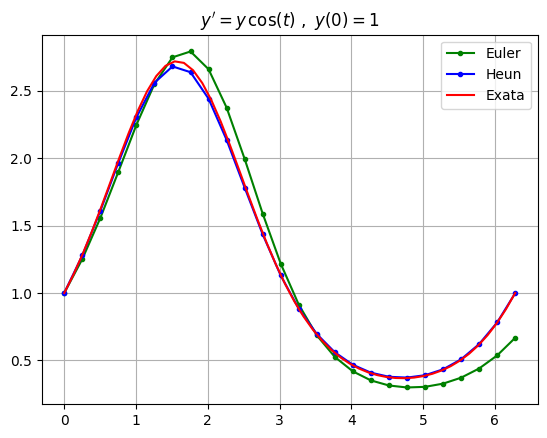

In [5]:
f = lambda t,y: y*np.cos(t)
y0 = 1; t0 = 0; tf = 2*np.pi;
N = 25; t = np.linspace(t0,tf,N+1)   # N passos: h = 2*pi/25 = 0.251...
y_euler = odeEuler(f,t,y0); plt.plot(t,y_euler,'g.-');
y_heun = odeHeun(f,t,y0); plt.plot(t,y_heun,'b.-');
t_exact = np.linspace(t0,tf,50)
y_exact = np.exp(np.sin(t_exact))
plt.plot(t_exact,y_exact,'r')
plt.grid(True), plt.title(r"$y' = y \, \cos(t) \ , \ y(0)=1$")
plt.legend(["Euler","Heun","Exata"])
plt.show()

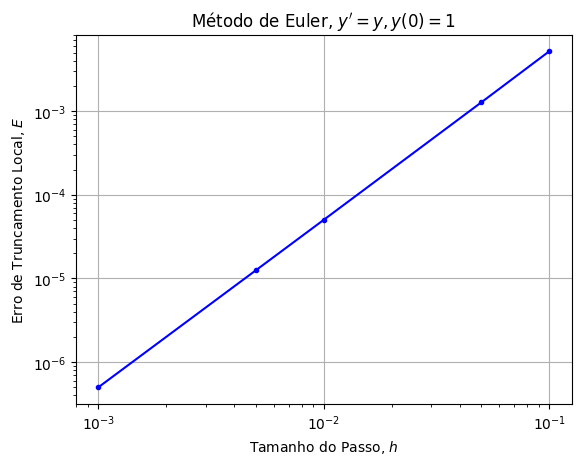

A ordem do método é 1.008325982940494


In [6]:
f = lambda t,y: y
y0 = 1;
h = [0.1,0.05,0.01,0.005,0.001]
E = np.zeros(len(h))
for n in range(0,len(h)):
    y = odeEuler(f,[0,h[n]],y0)
    y1 = y[1]
    y1_exact = np.exp(h[n])
    E[n] = np.abs(y1_exact - y1)

plt.loglog(h,E,'b.-'), plt.grid(True)
plt.title("Método de Euler, $y'=y,y(0)=1$")
plt.xlabel("Tamanho do Passo, $h$"), plt.ylabel("Erro de Truncamento Local, $E$")
plt.show()

p = (np.log(E[2])-np.log(E[1]))/(np.log(h[2])-np.log(h[1])) - 1

print("A ordem do método é",p)

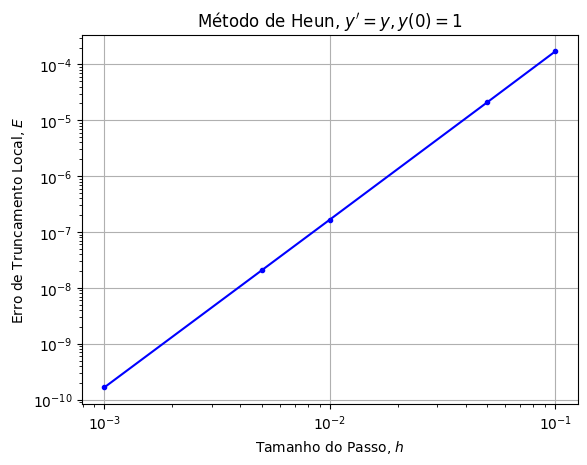

A ordem do método é 2.006241389698562


In [7]:
f = lambda t,y: y
y0 = 1;
h = [0.1,0.05,0.01,0.005,0.001]
E = np.zeros(len(h))
for n in range(0,len(h)):
    y = odeHeun(f,[0,h[n]],y0)
    y1 = y[1]
    y1_exact = np.exp(h[n])
    E[n] = np.abs(y1_exact - y1)

plt.loglog(h,E,'b.-'), plt.grid(True)
plt.title("Método de Heun, $y'=y,y(0)=1$")
plt.xlabel("Tamanho do Passo, $h$"), plt.ylabel("Erro de Truncamento Local, $E$")
plt.show()

p = (np.log(E[2])-np.log(E[1]))/(np.log(h[2])-np.log(h[1])) - 1

print("A ordem do método é",p)

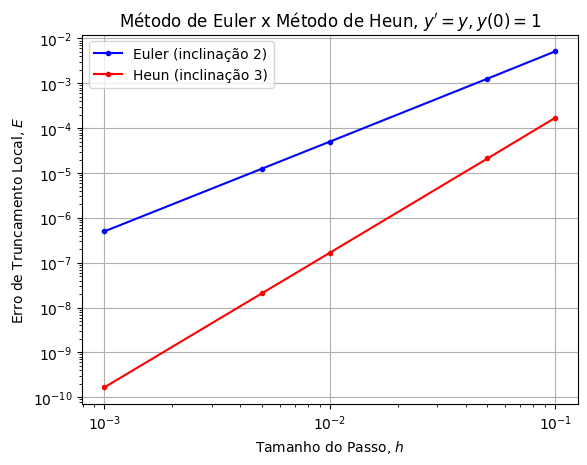

In [8]:
f = lambda t,y: y
y0 = 1;
h = [0.1,0.05,0.01,0.005,0.001]
E1 = np.zeros(len(h))
E2 = np.zeros(len(h))
for n in range(0,len(h)):
    y1_exact = np.exp(h[n])
    y = odeEuler(f,[0,h[n]],y0)
    E1[n] = np.abs(y1_exact - y[1])
    y = odeHeun(f,[0,h[n]],y0)
    E2[n] = np.abs(y1_exact - y[1])

plt.loglog(h,E1,'b.-'), plt.loglog(h,E2,'r.-'), plt.grid(True)
plt.title(r"Método de Euler x Método de Heun, $y'=y,y(0)=1$")
plt.xlabel(r"Tamanho do Passo, $h$"), plt.ylabel(r"Erro de Truncamento Local, $E$")
plt.legend(["Euler (inclinação 2)","Heun (inclinação 3)"])
plt.show()

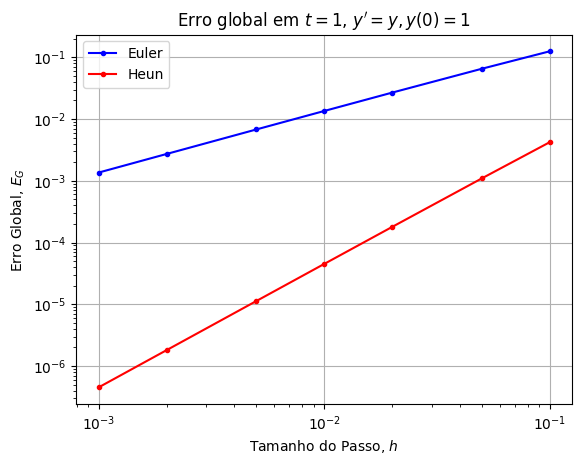

Inclinação do erro global - Euler: 0.9986794951592052
Inclinação do erro global - Heun:  1.9989176975822793


In [9]:
f = lambda t,y: y
y0 = 1; t0 = 0; tf = 1
N_values = [10,20,50,100,200,500,1000]
h = np.zeros(len(N_values)); EG1 = np.zeros(len(N_values)); EG2 = np.zeros(len(N_values))
for n, N in enumerate(N_values):
    t = np.linspace(t0,tf,N+1)
    h[n] = (tf - t0)/N
    EG1[n] = np.abs(odeEuler(f,t,y0)[-1] - np.exp(tf))
    EG2[n] = np.abs(odeHeun(f,t,y0)[-1] - np.exp(tf))

plt.loglog(h,EG1,'b.-',h,EG2,'r.-'), plt.grid(True)
plt.title(r"Erro global em $t=1$, $y'=y,y(0)=1$")
plt.xlabel(r"Tamanho do Passo, $h$"), plt.ylabel(r"Erro Global, $E_G$")
plt.legend(["Euler","Heun"])
plt.show()

p1 = (np.log(EG1[-1]) - np.log(EG1[-2]))/(np.log(h[-1]) - np.log(h[-2]))
p2 = (np.log(EG2[-1]) - np.log(EG2[-2]))/(np.log(h[-1]) - np.log(h[-2]))
print("Inclinação do erro global - Euler:", p1)
print("Inclinação do erro global - Heun: ", p2)

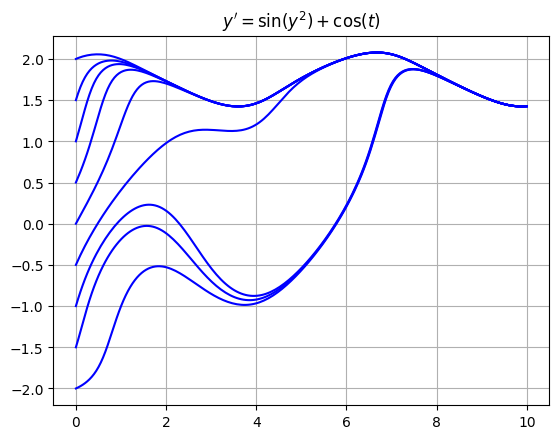

In [10]:
import scipy.integrate as spi

f = lambda y,t: np.sin(y**2) + np.cos(t)
t = np.linspace(0,10,200)
for y0 in np.linspace(-2,2,9):
    y = spi.odeint(f,y0,t)
    plt.plot(t,y,'b')

plt.grid(True), plt.title(r"$y' = \sin(y^2) + \cos(t)$")
plt.show()

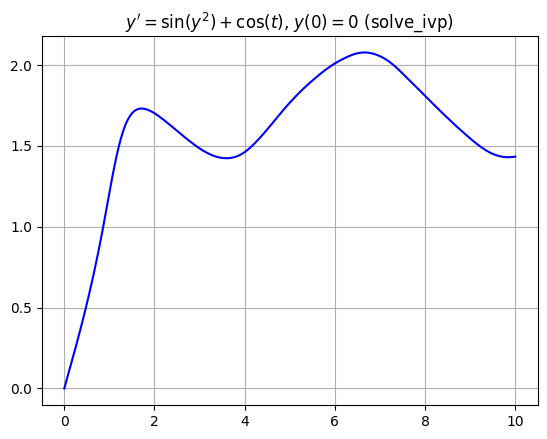

In [11]:
f = lambda t,y: np.sin(y**2) + np.cos(t)     # atenção: agora é f(t,y)
sol = spi.solve_ivp(f,[0,10],[0],t_eval=np.linspace(0,10,200))
plt.plot(sol.t,sol.y[0],'b'), plt.grid(True)
plt.title(r"$y' = \sin(y^2) + \cos(t)$, $y(0)=0$ (solve_ivp)")
plt.show()

Instante do evento: 5.596157879354392 min
Valor exato:        5.596157879354227 min


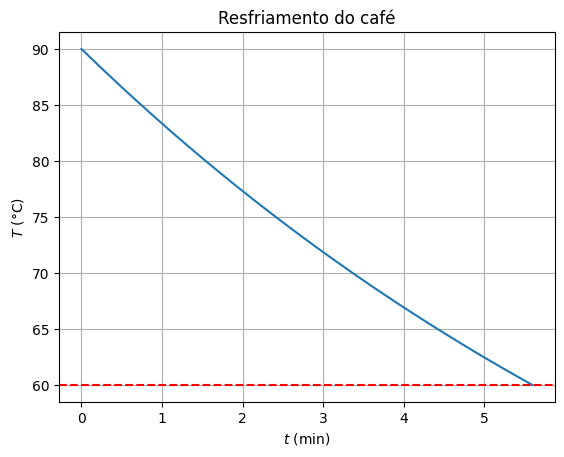

In [12]:
k = 0.1
f = lambda t,T: -k*(T - 20)
def chega_60(t,T):
    return T[0] - 60
chega_60.terminal = True     # interrompe a integração quando o evento ocorre

sol = spi.solve_ivp(f,[0,30],[90],events=chega_60,max_step=0.1)
print("Instante do evento:", sol.t_events[0][0], "min")
print("Valor exato:       ", np.log(70/40)/k, "min")

plt.plot(sol.t,sol.y[0]), plt.axhline(60,color='r',ls='--'), plt.grid(True)
plt.xlabel("$t$ (min)"), plt.ylabel("$T$ (°C)"), plt.title("Resfriamento do café")
plt.show()